In [51]:
from pathlib import Path
import sys

#mapping python to find SRC folder
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))



In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn


In [53]:
from src.har_data import load_features

data = load_features()

print("Training data:", data.X_train.shape)
print("Testing data:", data.X_test.shape)
print("Number of features:", len(data.feature_names))

Training data: (7352, 561)
Testing data: (2947, 561)
Number of features: 561


In [54]:
from src.har_data import load_features, ACTIVITY_NAMES

har = load_features()

X_train= har.X_train
y_train = har.y_train.ravel()

print("Training data:", X_train.shape)
print("Training labels:", y_train.shape)
print("Number of activities:", len(set(y_train)))

Training data: (7352, 561)
Training labels: (7352,)
Number of activities: 6


In [55]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_train)

print("Original shape:", X_train.shape)
print("Standardized shape:", X_scaled.shape)
print("Mean:", X_scaled.mean().round(4))
print("Standard deviation:", X_scaled.std().round(4))

Original shape: (7352, 561)
Standardized shape: (7352, 561)
Mean: 0.0
Standard deviation: 1.0


In [56]:
#PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=.95)
X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Number of principal components:", X_pca.shape[1])
print("Variance retained:", round(sum(pca.explained_variance_ratio_), 4))
print("New dataset shape:", X_pca.shape)


Original number of features: 561
Number of principal components: 102
Variance retained: 0.9508
New dataset shape: (7352, 102)


In [57]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_values = list(range(2, 11))
inertia_values = []

from sklearn.cluster import KMeans

# Reset both lists
k_values = list(range(2, 11))
inertia_values = []

# Run K-Means for each k
for k in k_values:
    print("Running k =", k)

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_pca)

    inertia_values.append(kmeans.inertia_)

# Display results
print("K values:", k_values)
print("Inertia values:", inertia_values)

Running k = 2
Running k = 3
Running k = 4
Running k = 5
Running k = 6
Running k = 7
Running k = 8
Running k = 9
Running k = 10
K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values: [2133133.678296123, 1878866.5973085642, 1773541.990139559, 1672340.5229394492, 1616137.3830192573, 1574488.3420656472, 1533301.8156848303, 1493942.7912603675, 1456333.7249464085]


In [58]:
from sklearn.cluster import KMeans

k_values = list(range(2, 11))
inertia_values = []

for k in k_values:
    print("Running k =", k)
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_pca)
    inertia_values.append(kmeans.inertia_)

Running k = 2
Running k = 3
Running k = 4
Running k = 5
Running k = 6
Running k = 7
Running k = 8
Running k = 9
Running k = 10


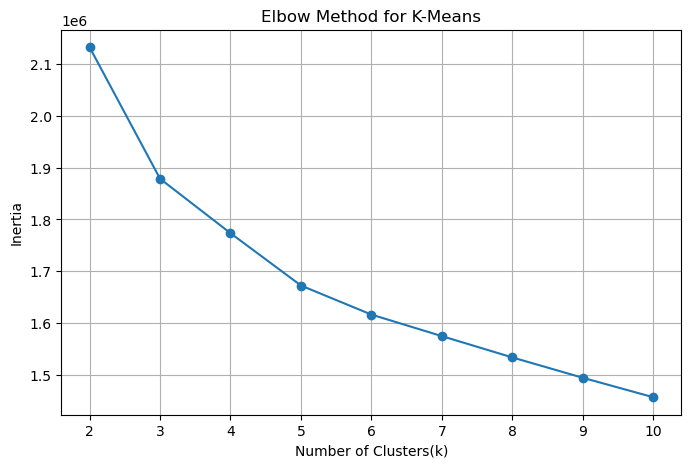

In [59]:
#Plotting elbow method

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker='o')
plt.xlabel("Number of Clusters(k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [60]:
for k in range(2,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )   

    cluster_labels = kmeans.fit_predict(X_pca)

    score = silhouette_score(X_pca, 
    cluster_labels,
    sample_size=2000,
    random_state=42
    )

    silhouette_values.append(score)

    print(f"Silhouette score for k={k}: {score:.4f}")


Silhouette score for k=2: 0.4182
Silhouette score for k=3: 0.3465
Silhouette score for k=4: 0.1757
Silhouette score for k=5: 0.1455
Silhouette score for k=6: 0.1217
Silhouette score for k=7: 0.0918
Silhouette score for k=8: 0.0977
Silhouette score for k=9: 0.0936
Silhouette score for k=10: 0.0984


In [61]:
#ARI

from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans

for k in[2,6]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_pca)

    ari_score = adjusted_rand_score(y_train, cluster_labels)

    print(f"Adjusted Rand Index for k={k}: {ari_score:.4f}")

    

Adjusted Rand Index for k=2: 0.3285
Adjusted Rand Index for k=6: 0.4196


In [62]:
import numpy as np
from sklearn.metrics import adjusted_rand_score

y_train_binary = np.where(y_train <= 3, 0, 1)

kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)   

clusters_2 = kmeans_2.fit_predict(X_pca)

ari_binary = adjusted_rand_score(y_train_binary,
 clusters_2
 )

print("ARI for moving vs.still:", round(ari_binary, 4))

ARI for moving vs.still: 0.9891


In [63]:
#Gaussian Mixture Model

from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score

for k in [2,6]:

    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        n_init=3
    )

    gmm_labels = gmm.fit_predict(X_pca)

    ari = adjusted_rand_score(y_train, gmm_labels)

    silhouette = silhouette_score(
    X_pca, 
    gmm_labels, 
    sample_size=2000, 
    random_state=42
    )

    print(f"\nGMM Results for k={k}:")
    print(f"Adjusted Rand Index: {ari:.4f}")
    print(f"Silhouette Score: {silhouette:.4f}")    

    if k == 2:
        ari_binary_gmm = adjusted_rand_score(
            y_train_binary, 
            gmm_labels)
        print(f"Moving vs Still ARI: {ari_binary_gmm:.4f}")


GMM Results for k=2:
Adjusted Rand Index: 0.3122
Silhouette Score: 0.4061
Moving vs Still ARI: 0.9368

GMM Results for k=6:
Adjusted Rand Index: 0.3090
Silhouette Score: 0.1120


In [71]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score

for k in [2, 6]:

    agg = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )   

    agg_labels = agg.fit_predict(X_pca)

    ari = adjusted_rand_score(y_train, agg_labels)

    silhouette = silhouette_score(
        X_pca, 
        agg_labels, 
        sample_size=2000, 
        random_state=42
    )       

    print(f"\nAgglomerative Clustering Results for k={k}:")
    print(f"Adjusted Rand Index: {ari:.4f}")
    print(f"Silhouette Score: {silhouette:.4f}")

    if k == 2:
        ari_binary = adjusted_rand_score(
            y_train_binary,
            agg_labels
        )
        print(f"Moving vs. Still ARI: {ari_binary:.4f}")


Agglomerative Clustering Results for k=2:
Adjusted Rand Index: 0.3319
Silhouette Score: 0.4180
Moving vs. Still ARI: 0.9995

Agglomerative Clustering Results for k=6:
Adjusted Rand Index: 0.4744
Silhouette Score: 0.1187


In [73]:
#visualizations

import pandas as pd

cluster_table = pd.crosstab(
    y_train, 
    agg_labels, 
    rownames=['True'], 
    colnames=['Cluster']
    )

print(cluster_table)

Cluster    0     1    2    3    4     5
True                                   
1        438     0  764   24    0     0
2        189     0  884    0    0     0
3        694     0  153  139    0     0
4          0  1009    1    0  255    21
5          0  1268    0    0  105     1
6          0    47    0    0  255  1105


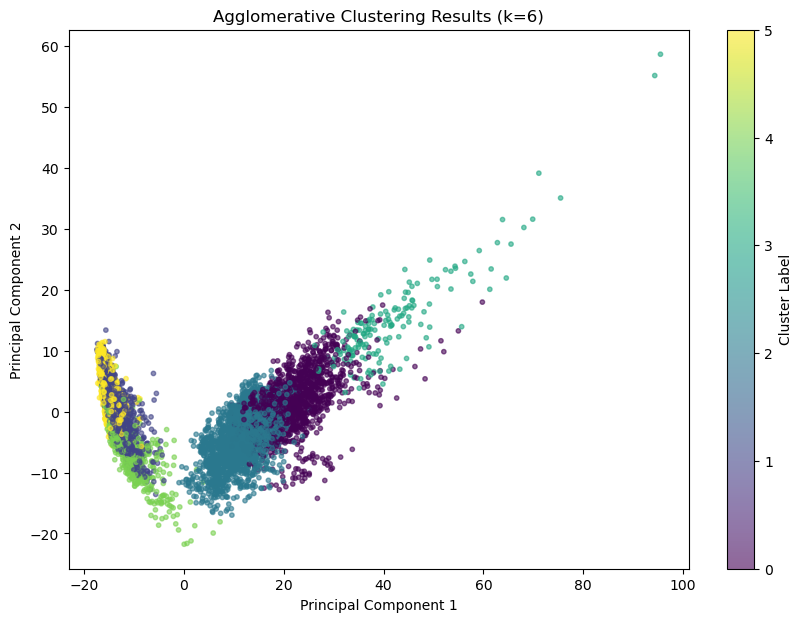

In [74]:
#scatterplot

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0], 
    X_pca[:, 1], 
    c=agg_labels, 
    cmap='viridis', 
    s=10,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clustering Results (k=6)")     

plt.colorbar(scatter, label='Cluster Label')    
plt.show()

In [5]:
#starting part 2

import sys
import os

project_root = os.path.dirname(os.getcwd())
sys.path.append(project_root)

print(project_root)
print(os.listdir(project_root))


/Users/liliankim/Desktop/AAI501FinalTeamProject
['PROJECT_PLAN.md', '.DS_Store', 'requirements.txt', 'README.md', 'results', '.gitignore', 'figures', '.git', 'data', 'notebooks', 'reports', 'src']


In [6]:
from src.har_data import load_features

data = load_features()

print(type(data))
print(data.keys() if isinstance(data, dict) else data)


<class 'src.har_data.HARData'>
HARData(X_train=      tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
0              0.288585          -0.020294          -0.132905   
1              0.278419          -0.016411          -0.123520   
2              0.279653          -0.019467          -0.113462   
3              0.279174          -0.026201          -0.123283   
4              0.276629          -0.016570          -0.115362   
...                 ...                ...                ...   
7347           0.299665          -0.057193          -0.181233   
7348           0.273853          -0.007749          -0.147468   
7349           0.273387          -0.017011          -0.045022   
7350           0.289654          -0.018843          -0.158281   
7351           0.351503          -0.012423          -0.203867   

      tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  \
0            -0.995279         -0.983111         -0.913526         -0.995112   
1           

In [9]:
print("Training subjects:", sorted(set(data.subject_train)))
print("Testing subjects:", sorted(set(data.subject_test)))

print("Number of training subjects:", len(set(data.subject_train)))
print("Number of testing subject:", len(set(data.subject_test)))



Training subjects: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Testing subjects: [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Number of training subjects: 21
Number of testing subject: 9


In [12]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score,classification_report

model = LinearSVC(C=0.1, random_state=42)

model.fit(data.X_train, data.y_train)

print("Model trained")

Model trained


In [15]:
#testing on 9 unseen subjects

y_pred = model.predict(data.X_test)

accuracy = accuracy_score(data.y_test, y_pred)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.9633525619273838


In [19]:
import pandas as pd

subject_results = pd.DataFrame({
    "Subject": data.subject_test,
    "True Label": data.y_test,
    "Predicted Label": y_pred

})

subject_results["Correct"] = (
    subject_results["True Label"] == subject_results["Predicted Label"]
)

accuracy_by_subject = subject_results.groupby("Subject")["Correct"].mean()

print(accuracy_by_subject)

Subject
2     0.986755
4     0.974763
9     0.878472
10    0.877551
12    0.968750
13    0.993884
18    0.978022
20    0.985876
24    1.000000
Name: Correct, dtype: float64


In [30]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
import pandas as pd

logo = LeaveOneGroupOut()

# Use a NEW list name
loso_records = []

for train_idx, test_idx in logo.split(
    data.X_train,
    data.y_train,
    groups=data.subject_train
):

    # Training data: all subjects except the one being left out
    X_train_fold = data.X_train.iloc[train_idx]
    y_train_fold = data.y_train[train_idx]

    # Testing data: the subject being left out
    X_test_fold = data.X_train.iloc[test_idx]
    y_test_fold = data.y_train[test_idx]

    # Train model
    model_fold = LinearSVC(C=0.1, random_state=42)
    model_fold.fit(X_train_fold, y_train_fold)

    # Make predictions
    predictions = model_fold.predict(X_test_fold)

    # Calculate accuracy
    accuracy = accuracy_score(y_test_fold, predictions)

    # Identify the subject
    subject = data.subject_train[test_idx][0]

    # Save results in our list
    loso_records.append({
        "Subject": subject,
        "Accuracy": accuracy
    })

# Convert list to DataFrame AFTER the loop
loso_df = pd.DataFrame(loso_records)

print(loso_df)
print("\nMean LOSO Accuracy:", loso_df["Accuracy"].mean())



    Subject  Accuracy
0         1  0.994236
1         3  0.985337
2         5  0.897351
3         6  0.855385
4         7  0.938312
5         8  0.957295
6        11  1.000000
7        14  0.708978
8        15  0.996951
9        16  0.778689
10       17  0.975543
11       19  0.941667
12       21  0.963235
13       22  0.993769
14       23  0.983871
15       25  0.929095
16       26  0.992347
17       27  0.984043
18       28  0.931937
19       29  0.982558
20       30  0.992167

Mean LOSO Accuracy: 0.9420365445464625


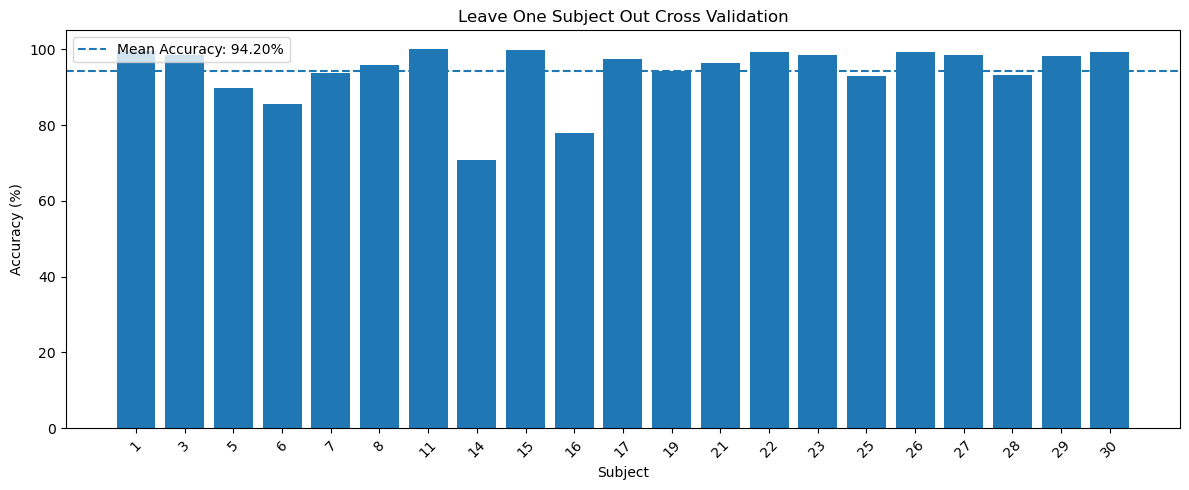

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    loso_df["Subject"].astype(str),
    loso_df["Accuracy"] * 100
)

plt.axhline(
    y=loso_df["Accuracy"].mean() * 100,
    linestyle="--",
    label=f"Mean Accuracy: {loso_df['Accuracy'].mean()*100:.2f}%"
)

plt.xlabel("Subject")
plt.ylabel("Accuracy (%)")
plt.title("Leave One Subject Out Cross Validation")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()